In [17]:
%load_ext autoreload
%autoreload 2
import sys
sys.path.append("..")

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from src.config import PROCESSED, ROOT
from src.indicators import atr
import itertools
from src.backtest import simular_trade, backtest

df = pd.read_parquet(PROCESSED)
df["atr"] = atr(df, 14)

In [19]:
o, h, l, c = (df[col].values for col in ["open", "high", "low", "close"])
print(simular_trade(o, h, l, c, i=1000, direccion=1, sl_dist=2.0, tp_dist=3.0, max_velas=24, coste=0.25))
print(simular_trade(o, h, l, c, i=1000, direccion=-1, sl_dist=2.0, tp_dist=3.0, max_velas=24, coste=0.25))

{'entrada_idx': 1000, 'direccion': 1, 'entrada': np.float64(1567.03), 'salida': np.float64(1565.03), 'motivo': 'SL', 'velas': 1, 'pnl': np.float64(-2.25), 'R': np.float64(-1.125)}
{'entrada_idx': 1000, 'direccion': -1, 'entrada': np.float64(1567.03), 'salida': np.float64(1569.03), 'motivo': 'SL', 'velas': 16, 'pnl': np.float64(-2.25), 'R': np.float64(-1.125)}


In [20]:
df.iloc[1000:1024][["open", "high", "low", "close"]]

,open,high,low,close
datetime,,,,
2020-01-07 15:20:00,1567.03,1567.54,1564.69,1565.21
2020-01-07 15:25:00,1565.23,1566.52,1565.19,1566.35
2020-01-07 15:30:00,1566.35,1566.81,1565.49,1566.49
2020-01-07 15:35:00,1566.40,1567.51,1566.38,1567.29
2020-01-07 15:40:00,1567.29,1567.44,1566.47,1567.37
2020-01-07 15:45:00,1567.37,1567.77,1566.87,1567.36
2020-01-07 15:50:00,1567.38,1568.27,1567.26,1567.39
2020-01-07 15:55:00,1567.39,1568.31,1567.25,1568.18
2020-01-07 16:00:00,1568.18,1568.57,1567.16,1567.50


In [21]:
rng = np.random.default_rng(0)
señales_pocas = pd.Series(rng.choice([0, 1, -1], size=len(df), p=[0.998, 0.001, 0.001]), index=df.index)
trades_pocas = backtest(df, señales_pocas, sl_mult=1.5, tp_mult=2.0, max_velas=24, coste=0.25)
print(len(trades_pocas), trades_pocas["R"].mean())
trades_pocas.groupby(df.index[trades_pocas["entrada_idx"]].year)["R"].agg(["mean", "count"])

993 -0.1471766384599079


,mean,count
datetime,,
2020,-0.159395,142
2021,-0.283060,146
2022,-0.277293,147
2023,-0.128198,157
2024,-0.273924,127
2025,0.061928,154
2026,0.032960,120


In [22]:
rng = np.random.default_rng(0)
señales_ctrl = pd.Series(rng.choice([0, 1, -1], size=len(df), p=[0.98, 0.01, 0.01]), index=df.index)
trades = backtest(df, señales_ctrl, sl_mult=1.5, tp_mult=2.0, max_velas=24, coste=0.25)
print(len(trades), trades["R"].mean())
trades.groupby(df.index[trades["entrada_idx"]].year)["R"].agg(["mean", "count"])


8416 -0.13240933402634328


,mean,count
datetime,,
2020,-0.081619,1242
2021,-0.179887,1263
2022,-0.165457,1196
2023,-0.179012,1259
2024,-0.091607,1200
2025,-0.113135,1289
2026,-0.110409,967


In [23]:
control = trades.copy()
control.to_parquet(ROOT / "reports" / "control_aleatorio.parquet")

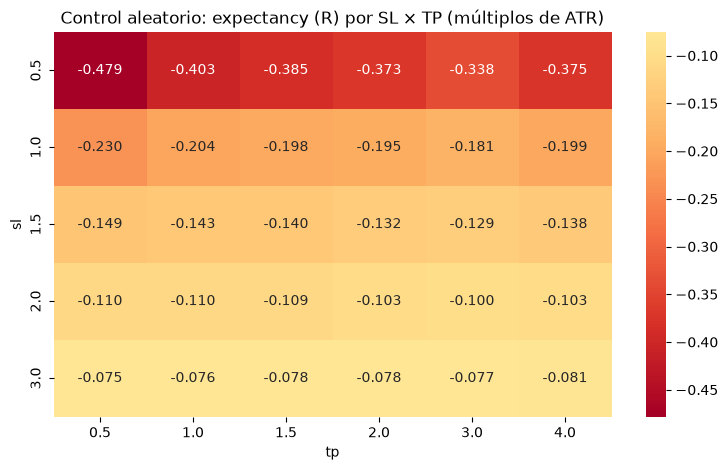

In [24]:
sl_list = [0.5, 1.0, 1.5, 2.0, 3.0]
tp_list = [0.5, 1.0, 1.5, 2.0, 3.0, 4.0]

filas = []
for sl_m, tp_m in itertools.product(sl_list, tp_list):
    t = backtest(df, señales_ctrl, sl_mult=sl_m, tp_mult=tp_m, max_velas=24, coste=0.25)
    filas.append({"sl": sl_m, "tp": tp_m,
                  "expR": t["R"].mean(),
                  "winrate": (t["R"] > 0).mean(),
                  "n": len(t)})

grid_ctrl = pd.DataFrame(filas)
tabla = grid_ctrl.pivot(index="sl", columns="tp", values="expR")

plt.figure(figsize=(9, 5))
sns.heatmap(tabla, annot=True, fmt=".3f", cmap="RdYlGn", center=0)
plt.title("Control aleatorio: expectancy (R) por SL × TP (múltiplos de ATR)")
plt.show()

In [25]:
grid_ctrl.query("sl == 2.0 and tp == 0.5")

,sl,tp,expR,winrate,n
18,2.0,0.5,-0.109737,0.758583,9233
